# EN4554 Assignment 1, Part 1: LoRA+ on SmolVLM-256M
## Notebook 02: the learning-rate grid (Step 5 of the brief)

**This notebook tests**
* **H1:** the best accuracy is reached with η_B much larger than η_A (ratio λ = η_B/η_A > 1), not with equal learning rates. This is the vision version of Figures 3 and 4 in the LoRA+ paper.
* **H2:** the gain of the best LoRA+ over the best plain LoRA is **larger on TextVQA** (hard, 32.8% zero-shot) than on **VQAv2** (easy, 45.3% zero-shot).

**How**
Each training run uses one pair (η_A, λ):
* λ = 1 is **plain LoRA** (the standard setup).
* λ > 1 is **LoRA+**.

Every run starts from the same pretrained model, uses the same 2,000 training questions and the same seed, trains for the same number of steps, and is scored on the same 500 eval questions. The only thing that changes is the two learning rates.



Runtime used: **T4 GPU**.

In [ ]:
!pip install -q "transformers==5.19.0" "peft==0.21.2" "datasets==5.1.0" accelerate
!pip uninstall -y -q torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 43.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 14.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:
import os, sys, re, json, time, math, random, collections
import numpy as np
import torch

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/EN4554_LoRAplus"
else:
    ROOT = "./EN4554_LoRAplus"
DATA_DIR, RES_DIR = f"{ROOT}/data", f"{ROOT}/results"
os.makedirs(RES_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"                 # fp16 mixed precision on the T4 (no bf16 on T4)
SEED = 42

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

# ---------------- experiment settings ----------------
MODEL_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"
RANK, ALPHA, DROPOUT = 8, 8, 0.0           # alpha = r = 8, as in the paper's Figures 3 and 4
# LoRA on every attention + MLP linear layer of BOTH the vision encoder and the language model
TARGET = r".*\.(vision_model|text_model)\..*\.(q_proj|k_proj|v_proj|o_proj|out_proj|gate_proj|up_proj|down_proj|fc1|fc2)"
EPOCHS, BATCH = 2, 16                       # 2 x 2000/16 = 250 optimiser steps per run
WARMUP_FRAC, MAX_GRAD_NORM = 0.06, 1.0      # linear warm-up for 6% of steps, then linear decay to 0

ETA_A = [1e-4, 2e-4, 4e-4, 8e-4, 1.6e-3]    # learning rate of A
# ratios lambda = eta_B / eta_A, in the order they are run (most important first).
# lambda = 1 is plain LoRA. The paper reports lambda ~ 2^2-2^3 for this initialisation (B = 0) and 2^4 as a common default.
GRID = {
    "textvqa": [1, 16, 4, 2, 8, 32],        # hard task: full grid for H1 (30 runs)
    "vqav2":   [1, 16, 4],                  # easy task: smaller grid for H2 (15 runs)
}
# Order in which (task, lambda) rows are run. The rows both hypotheses need come first,
# so if Colab's GPU quota runs out, H1 and H2 both already have data. The extra TextVQA rows come last.
RUN_ORDER = [("textvqa", 1), ("textvqa", 16), ("textvqa", 4),
             ("vqav2", 1), ("vqav2", 16), ("vqav2", 4),
             ("textvqa", 2), ("textvqa", 8), ("textvqa", 32)]
SUBSETS = {"textvqa": ("textvqa_train", "textvqa_eval"), "vqav2": ("vqav2_train", "vqav2_eval")}
EVAL_BATCH = 32

import transformers, peft, datasets
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__,
      "| device", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

Mounted at /content/drive
torch 2.11.0+cu130 | transformers 5.19.0 | peft 0.21.2 | device cuda Tesla T4


## 1. Data, prompt and metric
These are the same as notebook 01: the same subsets from Drive, the same prompt, and the same VQA accuracy.

**Training target:** each question has 10 human answers, and we train on the **most common** one. The loss is computed **only on the answer tokens**. The image and question tokens get label `-100`, so they are ignored.

**Speed-up: images are pre-processed once per session.** SmolVLM's image processor is slow on Colab's CPU: it enlarges every image to 2048 px and then shrinks it to 512 px. Doing that for every batch of every run left the GPU waiting most of the time (about 13 min per run). So each task's images are processed **once**, kept in RAM as 8-bit images (about 2 GB per task), and reused by every run.
This is **exact**: the processor's pixels are whole numbers 0–255, so storing them as 8-bit loses nothing. The check below compares a cached batch with a freshly processed one.

In [ ]:
from datasets import load_from_disk
from transformers import AutoProcessor, AutoModelForImageTextToText

data = {task: (load_from_disk(f"{DATA_DIR}/{tr}"), load_from_disk(f"{DATA_DIR}/{ev}")) for task, (tr, ev) in SUBSETS.items()}
for task, (tr, ev) in data.items():
    print(f"{task:8s} train {len(tr)}  eval {len(ev)}")

processor = AutoProcessor.from_pretrained(MODEL_ID, do_image_splitting=False)
tok = processor.tokenizer
EOU = "<end_of_utterance>"
PROMPT_SUFFIX = " Answer the question using a single word or phrase."

def build_prompt(question):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question + PROMPT_SUFFIX}]}]
    return processor.apply_chat_template(msgs, add_generation_prompt=True)

def target_answer(answers):
    return collections.Counter(answers).most_common(1)[0][0]

def collate_train(rows):
    tok.padding_side = "right"
    answers = [target_answer(r["answers"]) for r in rows]
    texts = [build_prompt(r["question"]) + " " + a + EOU for r, a in zip(rows, answers)]
    batch = processor(text=texts, images=[[r["image"]] for r in rows], return_tensors="pt", padding=True)
    labels = torch.full_like(batch["input_ids"], -100)
    for i, a in enumerate(answers):                      # keep loss only on " answer<end_of_utterance>"
        n = len(tok(" " + a + EOU, add_special_tokens=False).input_ids)
        L = int(batch["attention_mask"][i].sum())
        labels[i, L - n:L] = batch["input_ids"][i, L - n:L]
    batch["labels"] = labels
    return batch

# check the masking once: the decoded label tokens must be exactly the answers
_b = collate_train([data["textvqa"][0][i] for i in range(3)])
for i in range(3):
    lab = _b["labels"][i]
    print("   trains on:", repr(tok.decode(lab[lab != -100])))

# ---- VQA accuracy (same as notebook 01) ----
_CONTRACTIONS = {"dont": "don't", "doesnt": "doesn't", "isnt": "isn't", "arent": "aren't", "cant": "can't",
                 "wont": "won't", "didnt": "didn't", "wasnt": "wasn't", "werent": "weren't", "couldnt": "couldn't",
                 "shouldnt": "shouldn't", "wouldnt": "wouldn't", "hasnt": "hasn't", "havent": "haven't",
                 "im": "i'm", "ive": "i've", "youre": "you're", "theyre": "they're", "thats": "that's",
                 "whats": "what's", "wheres": "where's", "hes": "he's", "shes": "she's", "lets": "let's"}
_NUMS = {"none": "0", "zero": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5",
         "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10"}
_ARTICLES = {"a", "an", "the"}
_PUNCT = [";", "/", "[", "]", '"', "{", "}", "(", ")", "=", "+", "\\", "_", "-", ">", "<", "@", "`", ",", "?", "!"]
_PERIOD = re.compile(r"(?!<=\d)(\.)(?!\d)")
_COMMA = re.compile(r"(\d)(,)(\d)")

def normalize_answer(s):
    s = s.replace("\n", " ").replace("\t", " ").strip().lower()
    out = s
    for p in _PUNCT:
        if (p + " " in s or " " + p in s) or _COMMA.search(s):
            out = out.replace(p, "")
        else:
            out = out.replace(p, " ")
    out = _PERIOD.sub("", out)
    words = []
    for w in out.split():
        w = _NUMS.get(w, w)
        if w in _ARTICLES:
            continue
        words.append(_CONTRACTIONS.get(w, w))
    return " ".join(words)

def vqa_score(pred, answers):
    p = normalize_answer(pred)
    gts = [normalize_answer(a) for a in answers]
    return float(np.mean([min(1.0, sum(g == p for g in gts[:i] + gts[i + 1:]) / 3.0) for i in range(len(gts))]))

# ---------------- one-time pre-processing cache ----------------
_ip = processor.image_processor
MEAN = torch.tensor(_ip.image_mean).view(1, 3, 1, 1)
STD = torch.tensor(_ip.image_std).view(1, 3, 1, 1)
RESCALE = _ip.rescale_factor

def to_uint8(pv):                  # processor output (B,1,3,H,W) floats -> (B,3,H,W) uint8, exact
    return ((pv[:, 0] * STD + MEAN) / RESCALE).round().clamp(0, 255).to(torch.uint8)

def from_uint8(u8, dtype):         # (B,3,H,W) uint8 on any device -> (B,1,3,H,W) normalised, as the processor makes it
    x = (u8.float() * RESCALE - MEAN.to(u8.device)) / STD.to(u8.device)
    return x.to(dtype)[:, None]

CACHE = {}

def prepare(task, split):
    # run the slow processor ONCE for every example of data[task] ('train' or 'eval'); keep token ids + uint8 images
    if (task, split) in CACHE:
        return CACHE[(task, split)]
    for k in [k for k in CACHE if k[0] != task]:      # keep only one task in RAM at a time
        del CACHE[k]
    ds = data[task][0 if split == "train" else 1]
    t, ids, n_ans, imgs = time.time(), [], [], []
    tok.padding_side = "right"
    for i in range(0, len(ds), 64):
        chunk = ds[i:i + 64]
        if split == "train":
            answers = [target_answer(a) for a in chunk["answers"]]
            texts = [build_prompt(q) + " " + a + EOU for q, a in zip(chunk["question"], answers)]
            n_ans += [len(tok(" " + a + EOU, add_special_tokens=False).input_ids) for a in answers]
        else:
            texts = [build_prompt(q) for q in chunk["question"]]
        b = processor(text=texts, images=[[im] for im in chunk["image"]], return_tensors="pt", padding=True)
        ids += [b["input_ids"][k, :int(b["attention_mask"][k].sum())].clone() for k in range(len(texts))]
        imgs.append(to_uint8(b["pixel_values"]))
    CACHE[(task, split)] = c = {"img": torch.cat(imgs), "ids": ids, "n_ans": n_ans, "answers": list(ds["answers"])}
    print(f"   prepared {task}/{split}: {len(ids)} examples in {time.time()-t:.0f}s", flush=True)
    return c

def make_batch(c, idx, train):
    # pad token ids (right for training, left for generation) and attach the cached images
    seqs = [c["ids"][i] for i in idx]
    L, B = max(len(x) for x in seqs), len(seqs)
    input_ids = torch.full((B, L), tok.pad_token_id, dtype=torch.long)
    attn = torch.zeros((B, L), dtype=torch.long)
    labels = torch.full((B, L), -100, dtype=torch.long) if train else None
    for k, (i, x) in enumerate(zip(idx, seqs)):
        n = len(x)
        if train:
            input_ids[k, :n] = x; attn[k, :n] = 1
            labels[k, n - c["n_ans"][i]:n] = x[n - c["n_ans"][i]:]      # loss only on " answer<end_of_utterance>"
        else:
            input_ids[k, L - n:] = x; attn[k, L - n:] = 1
    out = {"input_ids": input_ids, "attention_mask": attn, "img": c["img"][list(idx)]}
    if train:
        out["labels"] = labels
    return out

def to_model_inputs(b, dtype):
    # move a cached batch to the GPU and rebuild pixel_values / pixel_attention_mask
    img = b.pop("img").to(DEVICE)
    b = {k: v.to(DEVICE) for k, v in b.items()}
    b["pixel_values"] = from_uint8(img, dtype)
    b["pixel_attention_mask"] = torch.ones((img.shape[0], 1, img.shape[2], img.shape[3]), dtype=torch.long, device=DEVICE)
    return b

@torch.no_grad()
def evaluate(model, c, n=None, batch_size=EVAL_BATCH, max_new_tokens=10):
    model.eval()
    N = n or len(c["ids"])
    dtype = next(model.parameters()).dtype
    preds = []
    for i in range(0, N, batch_size):
        b = to_model_inputs(make_batch(c, range(i, min(N, i + batch_size)), train=False), dtype)
        out = model.generate(**b, max_new_tokens=max_new_tokens, do_sample=False)
        preds += [x.strip() for x in processor.batch_decode(out[:, b["input_ids"].shape[1]:], skip_special_tokens=True)]
    scores = [vqa_score(p, a) for p, a in zip(preds, c["answers"][:N])]
    return 100 * float(np.mean(scores)), 100 * float(np.std(scores, ddof=1) / np.sqrt(len(scores))), preds

# ---------------- check: a cached batch is identical to a freshly processed one ----------------
_c = prepare("textvqa", "train")
_fresh = collate_train([data["textvqa"][0][i] for i in range(4)])
_cached = make_batch(_c, range(4), train=True)
_pv = from_uint8(_cached["img"], torch.float32)
assert torch.equal(_fresh["input_ids"], _cached["input_ids"]) and torch.equal(_fresh["labels"], _cached["labels"])
assert torch.equal(_fresh["attention_mask"], _cached["attention_mask"])
print("   cache check: token ids and labels identical, max pixel difference =",
      f"{(_fresh['pixel_values'] - _pv).abs().max().item():.1e}")
_ce = prepare("textvqa", "eval")
tok.padding_side = "left"                          # generation uses left padding
_fresh_e = processor(text=[build_prompt(q) for q in data["textvqa"][1][:4]["question"]],
                     images=[[im] for im in data["textvqa"][1][:4]["image"]], return_tensors="pt", padding=True)
assert torch.equal(_fresh_e["input_ids"], make_batch(_ce, range(4), train=False)["input_ids"]), "left padding differs"
print("   cache check (eval, left-padded prompts): identical")

textvqa  train 2000  eval 500
vqav2    train 2000  eval 500


processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


... (3 outputs left out)

added_tokens.json:   0%|          | 0.00/4.74k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.55M [00:00<?, ?B/s]

   trains on: ' geuze boon<end_of_utterance>'
   trains on: ' yes<end_of_utterance>'
   trains on: ' upplandsmuseet<end_of_utterance>'
   prepared textvqa/train: 2000 examples in 277s
   cache check: token ids and labels identical, max pixel difference = 1.2e-07
   prepared textvqa/eval: 500 examples in 65s
   cache check (eval, left-padded prompts): identical


## 2. One training run = one (η_A, λ) pair
This is where LoRA+ happens. It is just **two optimiser parameter groups**:
* all `lora_A` matrices train with learning rate **η_A**;
* all `lora_B` matrices train with learning rate **η_B = λ · η_A**.

Everything else (warm-up, decay, gradient clipping, fp16 loss scaling) is identical for every run. A run whose loss becomes NaN/inf (learning rate too high) is stopped and recorded as **diverged**. That is a real outcome and shows up as an empty cell in the heat map.

In [ ]:
from peft import LoraConfig, get_peft_model
from torch.utils.data import DataLoader

def load_lora_model():
    dtype = torch.float16 if USE_AMP else torch.float32
    base = AutoModelForImageTextToText.from_pretrained(MODEL_ID, dtype=dtype).to(DEVICE)
    cfg = LoraConfig(r=RANK, lora_alpha=ALPHA, lora_dropout=DROPOUT, target_modules=TARGET)
    return get_peft_model(base, cfg)        # PEFT keeps the LoRA weights in fp32 even though the base is fp16

def results_file(task):
    return f"{RES_DIR}/grid_{task}.jsonl"

def load_results(task):
    if not os.path.exists(results_file(task)):
        return []
    with open(results_file(task)) as f:
        return [json.loads(l) for l in f if l.strip()]

def run_key(eta_a, ratio, seed):
    return f"{eta_a:.2e}|{ratio:g}|{seed}"

def train_one(task, eta_a, ratio, seed=SEED, epochs=EPOCHS, batch_size=BATCH, n_train=None, n_eval=None):
    ctr, cev = prepare(task, "train"), prepare(task, "eval")
    n_tr = n_train or len(ctr["ids"])
    set_seed(seed)                                     # same LoRA init + same data order for every run
    model = load_lora_model()
    A = [p for n, p in model.named_parameters() if p.requires_grad and "lora_A" in n]
    B = [p for n, p in model.named_parameters() if p.requires_grad and "lora_B" in n]
    assert len(A) == len(B) and len(A) + len(B) == sum(p.requires_grad for p in model.parameters())
    opt = torch.optim.AdamW([{"params": A, "lr": eta_a}, {"params": B, "lr": eta_a * ratio}], weight_decay=0.0)

    loader = DataLoader(range(n_tr), batch_size=batch_size, shuffle=True,          # same shuffle order as before
                        collate_fn=lambda idx: make_batch(ctr, idx, train=True),
                        generator=torch.Generator().manual_seed(seed))
    total = epochs * len(loader)
    warm = max(1, int(WARMUP_FRAC * total))
    sched = torch.optim.lr_scheduler.LambdaLR(            # scales BOTH groups by the same factor -> ratio is preserved
        opt, lambda s: (s + 1) / warm if s < warm else max(0.0, (total - s) / max(1, total - warm)))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    model.train()
    losses, bad, diverged, t0, step = [], 0, False, time.time(), 0
    for epoch in range(epochs):
        for batch in loader:
            batch = to_model_inputs(batch, torch.float16 if USE_AMP else torch.float32)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = model(**batch).loss
            if not torch.isfinite(loss):
                bad += 1
                opt.zero_grad(set_to_none=True)
                if bad >= 5:
                    diverged = True
                    break
                continue
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(A + B, MAX_GRAD_NORM)
            scaler.step(opt); scaler.update()
            opt.zero_grad(set_to_none=True); sched.step()
            losses.append(round(loss.item(), 4)); step += 1
        if diverged:
            break
    train_time = time.time() - t0

    if diverged:
        acc, se = None, None
    else:
        t1 = time.time()
        acc, se, _ = evaluate(model, cev, n=n_eval)
    rec = {"task": task, "eta_a": eta_a, "eta_b": eta_a * ratio, "ratio": ratio, "seed": seed,
           "acc": acc, "se": se, "diverged": diverged, "steps": step,
           "final_loss": round(float(np.mean(losses[-20:])), 4) if losses else None, "losses": losses,
           "train_time": round(train_time), "eval_time": None if diverged else round(time.time() - t1),
           "rank": RANK, "alpha": ALPHA, "epochs": epochs, "batch": batch_size, "n_train": n_tr, "n_eval": n_eval or len(cev["ids"])}
    del model, opt, A, B
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return rec

_m = load_lora_model(); _m.print_trainable_parameters(); del _m

model.safetensors: reconstructing file:   0%|          |  0.00B /  513MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

trainable params: 3,769,344 || all params: 260,254,272 || trainable%: 1.4483


## 3. Run the grid
* Runs go in order of importance: TextVQA λ = 1 (plain LoRA), 16 (the paper's common default) and 4, then the same three rows for VQAv2, and last the extra TextVQA rows λ = 2, 8, 32. So even a partial grid already answers H1 and H2.
* Before the first run of each task, its images are pre-processed once (a few minutes, printed as `prepared ...`).




In [ ]:
def run_grid(grid=GRID, eta_list=ETA_A, seed=SEED, order=RUN_ORDER, **kw):
    rows = [(t, r) for t, r in order if t in grid and r in grid[t]]
    rows += [(t, r) for t, ratios in grid.items() for r in ratios if (t, r) not in rows]
    todo = [(t, r, e) for t, r in rows for e in eta_list]
    done_keys = {t: {run_key(x["eta_a"], x["ratio"], x["seed"]) for x in load_results(t)} for t in grid}
    todo = [(t, r, e) for t, r, e in todo if run_key(e, r, seed) not in done_keys[t]]
    print(f"{len(todo)} runs to do")
    times = []
    for i, (task, ratio, eta_a) in enumerate(todo, 1):
        prepare(task, "train"); prepare(task, "eval")    # one-time image pre-processing, not counted in run time
        t = time.time()
        rec = train_one(task, eta_a, ratio, seed=seed, **kw)
        with open(results_file(task), "a") as f:
            f.write(json.dumps(rec) + "\n")
        times.append(time.time() - t)
        acc = "DIVERGED" if rec["diverged"] else f"{rec['acc']:5.1f} ± {1.96*rec['se']:.1f}"
        eta = np.mean(times) * (len(todo) - i) / 60
        print(f"[{i:2d}/{len(todo)}] {task:7s} eta_A={eta_a:.1e} lambda={ratio:<3g} eta_B={eta_a*ratio:.1e} | "
              f"acc {acc} | loss {rec['final_loss']} | {times[-1]:.0f}s | ~{eta:.0f} min left", flush=True)

run_grid()

10 runs to do


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

[ 1/10] textvqa eta_A=1.0e-04 lambda=8   eta_B=8.0e-04 | acc  41.3 ± 4.2 | loss 0.5333 | 361s | ~54 min left


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

[ 2/10] textvqa eta_A=2.0e-04 lambda=8   eta_B=1.6e-03 | acc  42.8 ± 4.2 | loss 0.5751 | 371s | ~49 min left


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

... (11 outputs left out)

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

[ 9/10] textvqa eta_A=8.0e-04 lambda=32  eta_B=2.6e-02 | acc   9.4 ± 2.5 | loss 2.4008 | 357s | ~6 min left


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

[10/10] textvqa eta_A=1.6e-03 lambda=32  eta_B=5.1e-02 | acc   7.0 ± 2.1 | loss 2.6448 | 349s | ~0 min left


## 4. Results: heat maps (the vision version of the paper's Figure 3)
* **x axis:** η_A. **y axis:** λ = η_B/η_A. The bottom row (λ = 1) is plain LoRA. Every row above it is LoRA+.
  This shows the same information as the paper's (η_A, η_B) grid, because η_B = λ·η_A. Rows of constant λ make "equal learning rates" a single row.
* **Red box:** best accuracy overall. **Blue box:** best plain-LoRA accuracy (λ = 1).
* **H1 is supported** if the red box sits in a row with λ > 1 and is clearly better than the blue one.


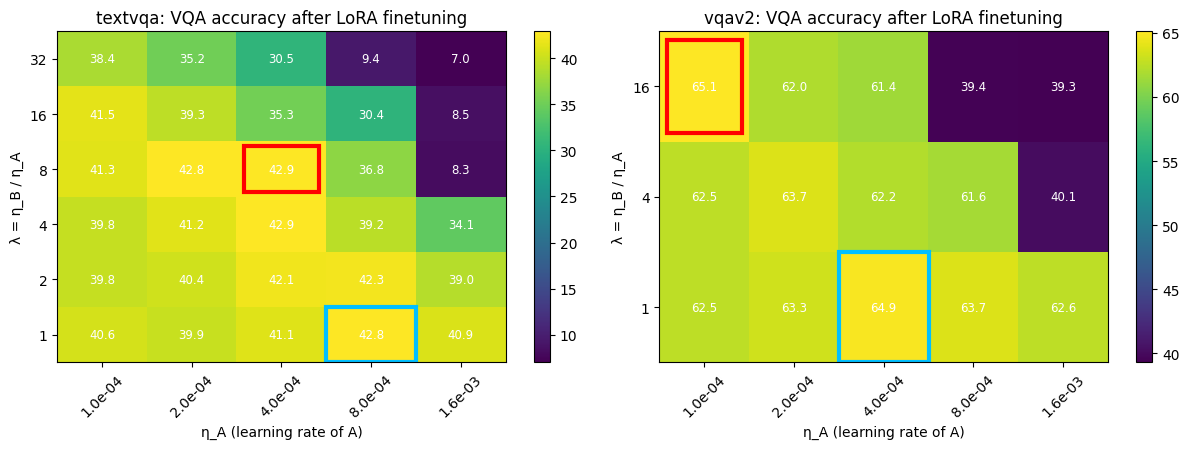

task     | zero-shot |          best LoRA (λ=1) |               best LoRA+ (λ>1) | gain
textvqa  |      32.8 |  42.8 ± 4.2 (η=8.0e-04) |  42.9 ± 4.2 (η_A=4.0e-04, λ=8) | +0.1
vqav2    |      45.3 |  64.9 ± 4.0 (η=4.0e-04) |  65.1 ± 3.9 (η_A=1.0e-04, λ=16) | +0.3


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def best_of(recs, cond):
    ok = [r for r in recs if cond(r) and not r["diverged"]]
    return max(ok, key=lambda r: r["acc"]) if ok else None

tasks = [t for t in GRID if load_results(t)]
fig, axes = plt.subplots(1, len(tasks), figsize=(6.2 * len(tasks), 4.6), squeeze=False)
summary = {}
for ax, task in zip(axes[0], tasks):
    recs = [r for r in load_results(task) if r["seed"] == SEED]
    etas = sorted({r["eta_a"] for r in recs}); ratios = sorted({r["ratio"] for r in recs})
    M = np.full((len(ratios), len(etas)), np.nan)
    for r in recs:
        if not r["diverged"]:
            M[ratios.index(r["ratio"]), etas.index(r["eta_a"])] = r["acc"]
    im = ax.imshow(M, origin="lower", cmap="viridis", aspect="auto")
    for i in range(len(ratios)):
        for j in range(len(etas)):
            ax.text(j, i, "div." if np.isnan(M[i, j]) and any(r["ratio"] == ratios[i] and r["eta_a"] == etas[j] for r in recs)
                    else ("" if np.isnan(M[i, j]) else f"{M[i, j]:.1f}"), ha="center", va="center", fontsize=8.5, color="white")
    ax.set_xticks(range(len(etas)), [f"{e:.1e}" for e in etas], rotation=45)
    ax.set_yticks(range(len(ratios)), [f"{r:g}" for r in ratios])
    ax.set_xlabel("η_A (learning rate of A)"); ax.set_ylabel("λ = η_B / η_A")
    ax.set_title(f"{task}: VQA accuracy after LoRA finetuning")
    plt.colorbar(im, ax=ax)
    b_all = best_of(recs, lambda r: True); b_lora = best_of(recs, lambda r: r["ratio"] == 1)
    for b, c, pad in [(b_lora, "deepskyblue", 0.0), (b_all, "red", 0.08)]:   # red drawn inside blue if they coincide
        if b:
            ax.add_patch(Rectangle((etas.index(b["eta_a"]) - .5 + pad, ratios.index(b["ratio"]) - .5 + pad),
                                   1 - 2 * pad, 1 - 2 * pad, fill=False, ec=c, lw=3))
    summary[task] = (b_lora, best_of(recs, lambda r: r["ratio"] > 1))
plt.tight_layout(); plt.savefig(f"{RES_DIR}/heatmaps.png", dpi=200); plt.show()

zs = json.load(open(f"{RES_DIR}/zeroshot.json")) if os.path.exists(f"{RES_DIR}/zeroshot.json") else {}
print(f"{'task':8s} | {'zero-shot':>9s} | {'best LoRA (λ=1)':>24s} | {'best LoRA+ (λ>1)':>30s} | gain")
for task, (bl, bp) in summary.items():
    z = zs.get(f"zeroshot_{task}", {}).get("acc", float("nan"))
    if bl and bp:
        print(f"{task:8s} | {z:9.1f} | {bl['acc']:5.1f} ± {1.96*bl['se']:.1f} (η={bl['eta_a']:.1e}) | "
              f"{bp['acc']:5.1f} ± {1.96*bp['se']:.1f} (η_A={bp['eta_a']:.1e}, λ={bp['ratio']:g}) | {bp['acc']-bl['acc']:+.1f}")

## 5. Convergence speed (the vision version of the paper's Figure 7)
This compares the training loss over steps for the best plain-LoRA run and the best LoRA+ run of each task. The claim being tested: LoRA+ reaches a low loss sooner ("up to ~2× speed-up").

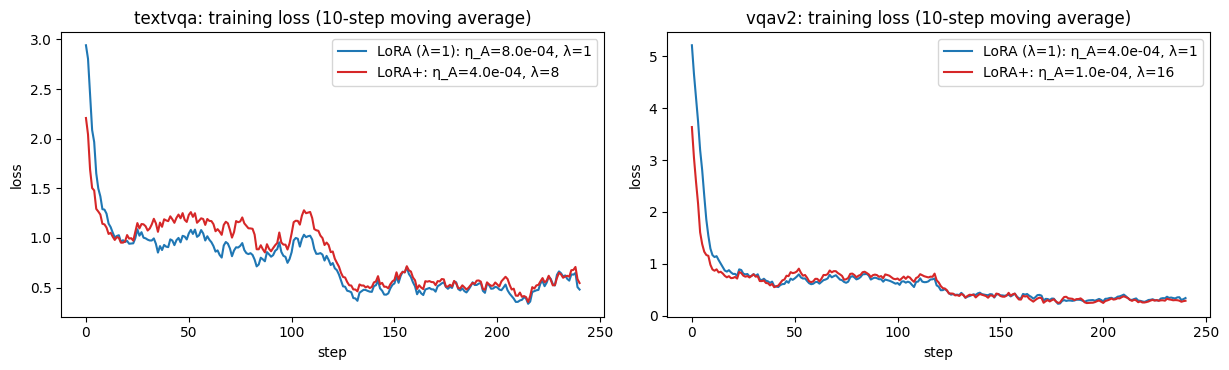

In [ ]:
def smooth(x, k=10):
    x = np.asarray(x, float)
    return np.convolve(x, np.ones(k) / k, mode="valid") if len(x) >= k else x

fig, axes = plt.subplots(1, len(summary), figsize=(6.2 * len(summary), 3.8), squeeze=False)
for ax, (task, (bl, bp)) in zip(axes[0], summary.items()):
    for r, lab, c in [(bl, "LoRA (λ=1)", "tab:blue"), (bp, "LoRA+", "tab:red")]:
        if r:
            ax.plot(smooth(r["losses"]), color=c, label=f"{lab}: η_A={r['eta_a']:.1e}, λ={r['ratio']:g}")
    ax.set_title(f"{task}: training loss (10-step moving average)"); ax.set_xlabel("step"); ax.set_ylabel("loss")
    ax.legend()
plt.tight_layout(); plt.savefig(f"{RES_DIR}/loss_curves.png", dpi=200); plt.show()